<a href="https://colab.research.google.com/github/TMoses001/nigerian-covid19-market-analysis/blob/main/Nigeria_COVID_Regimes_Corrected.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nigerian COVID-19 Market Regimes — Analysis Pipeline
**MScFE 690 Capstone — Impact of COVID-19 on Nigerian Financial Markets**

Fixes applied vs. the earlier versions:

1. **HMM regimes are relabeled by realized volatility** so "high-volatility regime" always means the same thing, regardless of hmmlearn's arbitrary internal state ordering.
2. **Bond tenors are cleaned independently**, not with a joint `dropna()` across all four maturities (which drops ~40% of rows and truncates the usable window to mid-2019).
3. **Correlation analysis uses yield *changes*, not raw yield levels** (levels are non-stationary and produce spurious ~0.95+ bond-to-bond correlations).
4. **GARCH(1,1) is actually fitted**, not just imported.
5. **Welch's t-test and Levene's test** are run for all period comparisons, per the Problem Statement's committed methodology.
6. The Brent **−64% day on 2020-04-21 is kept and footnoted** as a confirmed real event (global oil storage crisis), not removed as an outlier.



In [ ]:
!pip install -q arch hmmlearn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 12.5 MB/s eta 0:00:00


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from hmmlearn.hmm import GaussianHMM

pd.set_option("display.width", 150)


DATA_DIR = ""


## Step 1 — Data Collection

In [ ]:
brent = pd.read_csv(DATA_DIR + "Brent Oil.csv")
ngx = pd.read_csv(DATA_DIR + "NGX All-Share Index (ASI).csv")
usd_ngn = pd.read_csv(DATA_DIR + "USD_NGN Historical Data.csv")
bond = pd.read_csv(DATA_DIR + "Nigeria_Bond_Yields_2017_2025_Redone.csv")

print("Raw shapes:", brent.shape, ngx.shape, usd_ngn.shape, bond.shape)


Raw shapes: (2536, 2) (2208, 7) (2326, 7) (2198, 5)


## Step 2 — Data Cleaning & Preparation

Key change from the original script: **bond tenors are cleaned independently** (Step 2.6 below), not with a single joint `dropna()` across all four columns.

In [ ]:
for df in [brent, ngx, usd_ngn, bond]:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for df in [brent, ngx, usd_ngn]:
    df["Price"] = pd.to_numeric(df["Price"].astype(str).str.replace(",", "", regex=False), errors="coerce")

bond_cols = ["Nigeria_2Y_Bond_Yield", "Nigeria_5Y_Bond_Yield", "Nigeria_10Y_Bond_Yield", "Nigeria_20Y_Bond_Yield"]
for c in bond_cols:
    bond[c] = pd.to_numeric(bond[c].astype(str).str.replace(",", "", regex=False), errors="coerce")

for df in [brent, ngx, usd_ngn, bond]:
    df.sort_values("Date", inplace=True)
    df.drop_duplicates(subset="Date", keep="first", inplace=True)

# Restrict every series to the 2017-2025 study window
STUDY_START, STUDY_END = "2017-01-01", "2025-12-31"
brent = brent[(brent["Date"] >= STUDY_START) & (brent["Date"] <= STUDY_END)].copy()
ngx = ngx[(ngx["Date"] >= STUDY_START) & (ngx["Date"] <= STUDY_END)].copy()
usd_ngn = usd_ngn[(usd_ngn["Date"] >= STUDY_START) & (usd_ngn["Date"] <= STUDY_END)].copy()
bond = bond[(bond["Date"] >= STUDY_START) & (bond["Date"] <= STUDY_END)].copy()

brent = brent.dropna(subset=["Price"]).reset_index(drop=True)
ngx = ngx.dropna(subset=["Price"]).reset_index(drop=True)
usd_ngn = usd_ngn.dropna(subset=["Price"]).reset_index(drop=True)

print("Cleaned (2017-2025) shapes: Brent", brent.shape, " NGX", ngx.shape, " USD/NGN", usd_ngn.shape, " Bond (raw)", bond.shape)


Cleaned (2017-2025) shapes: Brent (2283, 2)  NGX (2208, 7)  USD/NGN (2326, 7)  Bond (raw) (2198, 5)


In [ ]:
# STEP 2.6 (CORRECTED) — clean each bond tenor INDEPENDENTLY, not jointly
bond_indep = bond[["Date"]].copy()
for c in bond_cols:
    s = bond[["Date", c]].dropna()
    print(f"{c}: {len(s)} / {len(bond)} non-missing")

# For analyses that need the full 4-tenor matrix simultaneously (PCA), we still need
# joint non-missingness, but we report it explicitly rather than silently truncating:
bond_full = bond.dropna(subset=bond_cols).copy().reset_index(drop=True)
print(f"\nJoint (all 4 tenors) non-missing: {len(bond_full)} / {len(bond)} rows "
      f"({100*(len(bond)-len(bond_full))/len(bond):.1f}% dropped)")
print("Joint-sample date range:", bond_full['Date'].min(), "to", bond_full['Date'].max())


Nigeria_2Y_Bond_Yield: 1797 / 2198 non-missing
Nigeria_5Y_Bond_Yield: 1682 / 2198 non-missing
Nigeria_10Y_Bond_Yield: 2147 / 2198 non-missing
Nigeria_20Y_Bond_Yield: 2140 / 2198 non-missing

Joint (all 4 tenors) non-missing: 1319 / 2198 rows (40.0% dropped)
Joint-sample date range: 2019-07-26 00:00:00 to 2025-12-01 00:00:00


## Step 3 — Exploratory Data Analysis

In [ ]:
for name, df in [("Brent", brent), ("NGX", ngx), ("USD/NGN", usd_ngn)]:
    print(f"\n--- {name} ---")
    print(df["Price"].describe().round(4))

print("\n--- Bond yields (joint-complete sample) ---")
print(bond_full[bond_cols].describe().round(4))



--- Brent ---
count    2283.0000
mean       70.5517
std        17.8648
min         9.1200
25%        61.0050
50%        70.8700
75%        80.9250
max       133.1800
Name: Price, dtype: float64

--- NGX ---
count      2208.0000
mean      54596.2146
std       32302.1328
min       20669.3800
25%       31202.7700
50%       41065.8750
75%       66590.6850
max      155645.0300
Name: Price, dtype: float64

--- USD/NGN ---
count    2326.0000
mean      629.8658
std       475.5793
min       304.0000
25%       305.9500
50%       409.8100
75%       773.0000
max      1681.3900
Name: Price, dtype: float64

--- Bond yields (joint-complete sample) ---
       Nigeria_2Y_Bond_Yield  Nigeria_5Y_Bond_Yield  Nigeria_10Y_Bond_Yield  Nigeria_20Y_Bond_Yield
count              1319.0000              1319.0000               1319.0000               1319.0000
mean                 12.3264                13.3496                 14.1056                 14.3380
std                   6.2651                 4.3118   

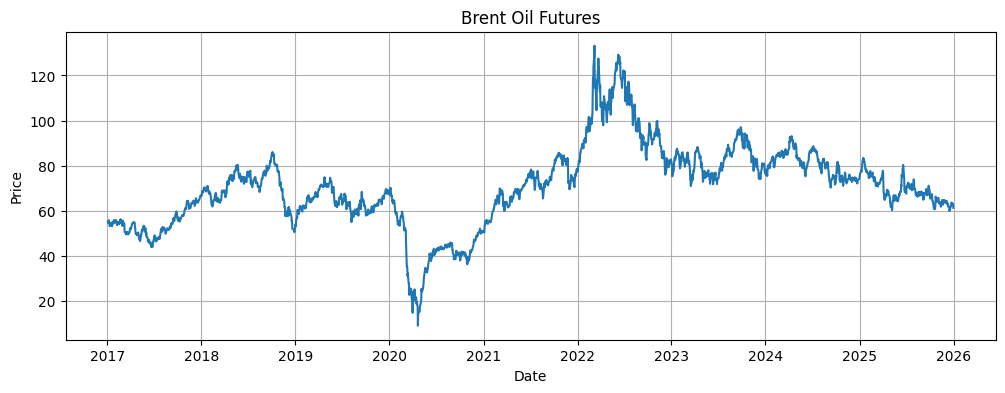

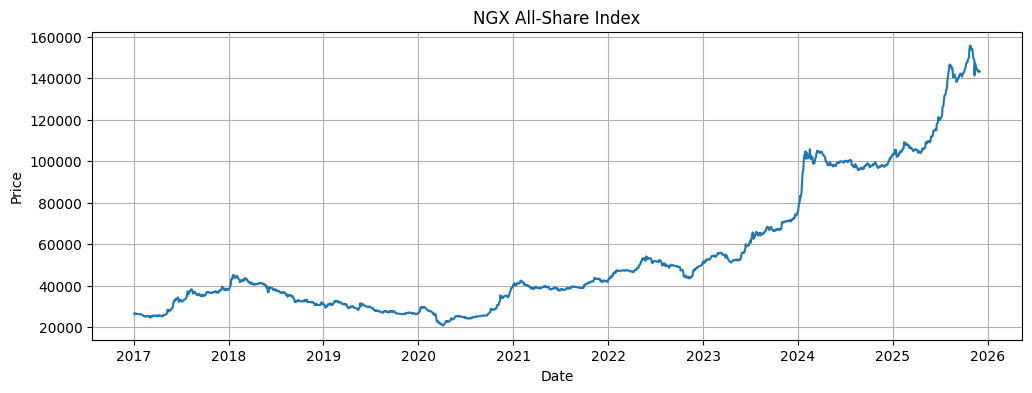

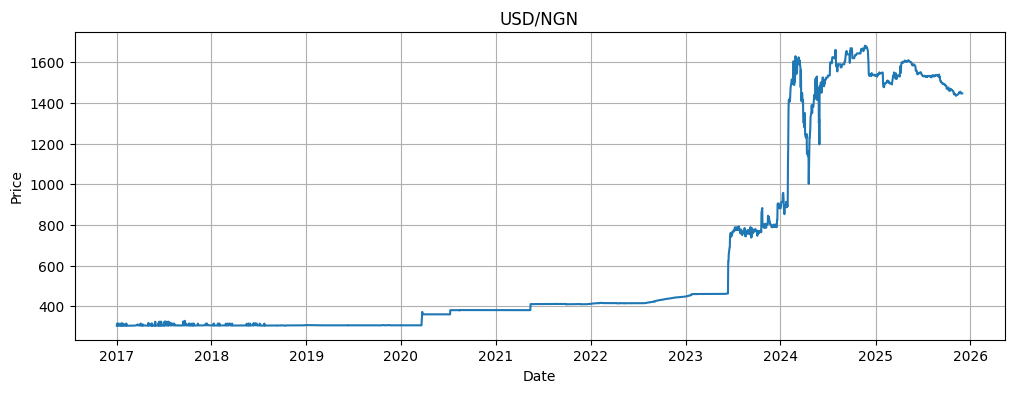

In [ ]:
for name, df in [("Brent Oil Futures", brent), ("NGX All-Share Index", ngx), ("USD/NGN", usd_ngn)]:
    plt.figure(figsize=(12, 4))
    plt.plot(df["Date"], df["Price"])
    plt.title(name); plt.xlabel("Date"); plt.ylabel("Price"); plt.grid(True)
    plt.show()


## Step 4 — Return & Volatility Calculation

In [ ]:
for df in [brent, ngx, usd_ngn]:
    df["Return"] = np.log(df["Price"] / df["Price"].shift(1))
    df["Volatility"] = df["Return"].rolling(20).std()

for c in bond_cols:
    bond_full[f"{c}_Change"] = bond_full[c].diff()
    bond_full[f"{c}_Volatility"] = bond_full[f"{c}_Change"].rolling(20).std()

for name, df in [("Brent", brent), ("NGX", ngx), ("USD/NGN", usd_ngn)]:
    print(f"\n--- {name} return stats ---")
    print(df["Return"].describe().round(6))



--- Brent return stats ---
count    2282.000000
mean        0.000047
std         0.031075
min        -0.643699
25%        -0.011249
50%         0.001257
75%         0.012724
max         0.412023
Name: Return, dtype: float64

--- NGX return stats ---
count    2207.000000
mean        0.000762
std         0.008752
min        -0.051741
25%        -0.002788
50%         0.000237
75%         0.004085
max         0.060478
Name: Return, dtype: float64

--- USD/NGN return stats ---
count    2325.000000
mean        0.000671
std         0.017118
min        -0.135614
25%        -0.000065
50%         0.000000
75%         0.000168
max         0.293655
Name: Return, dtype: float64


### Note on extreme single-day moves

The largest Brent move (**-64.4% on 2020-04-21**, price falling to ~$9/barrel) is a **confirmed real event**, not a data error: S&P Global and Reuters both reported dated Brent falling below $15/barrel around 21 April 2020 amid the global oil-demand collapse and storage crisis (the same episode in which WTI briefly traded negative). It is kept in the dataset. The other large Brent/USD-NGN swings (clustered Mar-May 2020, plus USD/NGN jumps in Jun 2023 and Jan/Apr/May 2024) correspond to the COVID oil crash and the 2023-2024 Naira float/devaluation events respectively — also genuine, not errors.

In [ ]:
extreme = brent.loc[brent["Return"].abs() > 0.15, ["Date", "Price", "Return"]]
print("Brent days with |log return| > 15%:")
print(extreme)


Brent days with |log return| > 15%:
          Date  Price    Return
812 2020-03-09  35.33 -0.255175
819 2020-03-18  22.79 -0.204811
827 2020-03-30  19.19 -0.154225
828 2020-03-31  14.85 -0.256389
830 2020-04-02  20.24  0.301613
831 2020-04-03  24.33  0.184049
835 2020-04-09  20.23 -0.220471
841 2020-04-21   9.12 -0.643699
842 2020-04-22  13.77  0.412023
851 2020-05-05  25.46  0.221574


## Step 5 — Time-Series Analysis: ARIMA

In [ ]:
ngx_returns = ngx[["Date", "Return"]].dropna().set_index("Date")

arima_model = ARIMA(ngx_returns["Return"], order=(1, 0, 1))
arima_result = arima_model.fit()
print(arima_result.summary())

resid = arima_result.resid
lb = sm_lb = None
from statsmodels.stats.diagnostic import acorr_ljungbox
lb_test = acorr_ljungbox(resid, lags=[1, 10, 20], return_df=True)
print("\nLjung-Box test on residuals:")
print(lb_test)

jb_stat, jb_p = stats.jarque_bera(resid)[:2]
print(f"\nJarque-Bera: stat={jb_stat:.3f}, p={jb_p:.6f}")
print(f"Residual kurtosis: {stats.kurtosis(resid, fisher=False):.3f}")


                               SARIMAX Results                                
Dep. Variable:                 Return   No. Observations:                 2207
Model:                 ARIMA(1, 0, 1)   Log Likelihood                7398.651
Date:                Sat, 10 Oct 2026   AIC                         -14789.302
Time:                        08:53:28   BIC                         -14766.504
Sample:                             0   HQIC                        -14780.973
                               - 2207                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0008      0.000      2.902      0.004       0.000       0.001
ar.L1          0.4733      0.052      9.074      0.000       0.371       0.576
ma.L1         -0.2453      0.059     -4.185      0.0

## Step 5b — GARCH(1,1) Volatility Model (actually fitted)

In [ ]:
garch_input = ngx_returns["Return"].dropna() * 100  # scale per arch convention
garch_model = arch_model(garch_input, vol="Garch", p=1, q=1, dist="normal")
garch_result = garch_model.fit(disp="off")
print(garch_result.summary())

omega = garch_result.params["omega"]
alpha1 = garch_result.params["alpha[1]"]
beta1 = garch_result.params["beta[1]"]
print(f"\nomega={omega:.4f}  alpha1={alpha1:.4f}  beta1={beta1:.4f}  persistence(alpha+beta)={alpha1+beta1:.4f}")


                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2601.34
Distribution:                  Normal   AIC:                           5210.68
Method:            Maximum Likelihood   BIC:                           5233.48
                                        No. Observations:                 2207
Date:                Sat, Oct 10 2026   Df Residuals:                     2206
Time:                        08:53:33   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu             0.0281  1.648e-02      1.704  8.838e-02 

## Step 6 — Sovereign Yield Curve Analysis: PCA (on yield CHANGES)

In [ ]:
yield_changes = bond_full[bond_cols].diff().dropna()

scaler = StandardScaler()
yc_scaled = scaler.fit_transform(yield_changes)

pca = PCA()
pca_scores_array = pca.fit_transform(yc_scaled)

explained_variance = pd.DataFrame({
    "Component": ["PC1", "PC2", "PC3", "PC4"],
    "Explained_Variance_Ratio": pca.explained_variance_ratio_,
    "Cumulative_Variance_Ratio": np.cumsum(pca.explained_variance_ratio_)
})
print("PCA explained variance:")
print(explained_variance.round(4))

pca_loadings = pd.DataFrame(pca.components_.T, index=bond_cols, columns=["PC1", "PC2", "PC3", "PC4"])
print("\nPCA loadings:")
print(pca_loadings.round(4))


PCA explained variance:
  Component  Explained_Variance_Ratio  Cumulative_Variance_Ratio
0       PC1                    0.3707                     0.3707
1       PC2                    0.2260                     0.5967
2       PC3                    0.2079                     0.8046
3       PC4                    0.1954                     1.0000

PCA loadings:
                           PC1     PC2     PC3     PC4
Nigeria_2Y_Bond_Yield   0.4916 -0.3964  0.7716  0.0758
Nigeria_5Y_Bond_Yield   0.5370 -0.2556 -0.4053 -0.6944
Nigeria_10Y_Bond_Yield  0.5444 -0.0630 -0.4485  0.7060
Nigeria_20Y_Bond_Yield  0.4166  0.8795  0.1979 -0.1171


## Step 7 — Correlation Analysis (CORRECTED: returns + yield *changes*, not levels)

In [ ]:
bond_chg = bond_full.set_index("Date")[[f"{c}_Change" for c in bond_cols]]

corr_data = pd.DataFrame({
    "NGX": ngx.set_index("Date")["Return"],
    "USD_NGN": usd_ngn.set_index("Date")["Return"],
    "Brent": brent.set_index("Date")["Return"],
}).join(bond_chg).dropna()

correlation_matrix = corr_data.corr()
print(f"n observations: {len(corr_data)}")
print("\nCorrelation matrix (returns / yield changes):")
print(correlation_matrix.round(4))


n observations: 1306

Correlation matrix (returns / yield changes):
                                  NGX  USD_NGN   Brent  Nigeria_2Y_Bond_Yield_Change  Nigeria_5Y_Bond_Yield_Change  Nigeria_10Y_Bond_Yield_Change  \
NGX                            1.0000   0.0435  0.0780                       -0.0196                       -0.0485                        -0.0148   
USD_NGN                        0.0435   1.0000 -0.0232                       -0.0107                        0.0107                         0.0258   
Brent                          0.0780  -0.0232  1.0000                        0.0023                        0.0218                        -0.0165   
Nigeria_2Y_Bond_Yield_Change  -0.0196  -0.0107  0.0023                        1.0000                        0.1831                         0.1734   
Nigeria_5Y_Bond_Yield_Change  -0.0485   0.0107  0.0218                        0.1831                        1.0000                         0.2171   
Nigeria_10Y_Bond_Yield_Change -0.0148 

## Step 8 — Hidden Markov Model Regime Detection (with CORRECTED regime labeling)

In [ ]:
hmm_data = ngx[["Date", "Return", "Volatility"]].dropna().copy()

hmm_scaler = StandardScaler()
hmm_features = hmm_scaler.fit_transform(hmm_data[["Return", "Volatility"]])

hmm_model = GaussianHMM(n_components=2, covariance_type="full", n_iter=1000, random_state=42)
hmm_model.fit(hmm_features)

raw_state = hmm_model.predict(hmm_features)
hmm_data["RawState"] = raw_state

transition_matrix = pd.DataFrame(hmm_model.transmat_, index=["State 0", "State 1"], columns=["State 0", "State 1"])
print("Transition matrix (raw state indices, order is arbitrary):")
print(transition_matrix.round(4))

# --- THE FIX: relabel states by actual mean volatility, so "High-Vol" always means high-vol ---
state_vol = hmm_data.groupby("RawState")["Volatility"].mean()
high_vol_state = state_vol.idxmax()
low_vol_state = state_vol.idxmin()
print(f"\nRaw state {high_vol_state} has higher mean volatility ({state_vol[high_vol_state]:.6f}) -> labeled 'High-Vol'")
print(f"Raw state {low_vol_state} has lower mean volatility ({state_vol[low_vol_state]:.6f}) -> labeled 'Low-Vol'")

hmm_data["Regime"] = np.where(hmm_data["RawState"] == high_vol_state, "High-Vol", "Low-Vol")

regime_statistics = hmm_data.groupby("Regime")[["Return", "Volatility"]].agg(["mean", "std", "min", "max", "count"])
print("\nRegime statistics (after correct labeling):")
print(regime_statistics.round(6))


Transition matrix (raw state indices, order is arbitrary):
         State 0  State 1
State 0   0.9740   0.0260
State 1   0.0144   0.9856

Raw state 0 has higher mean volatility (0.011622) -> labeled 'High-Vol'
Raw state 1 has lower mean volatility (0.005342) -> labeled 'Low-Vol'

Regime statistics (after correct labeling):
            Return                                    Volatility                                    
              mean      std       min       max count       mean       std       min       max count
Regime                                                                                              
High-Vol  0.001563  0.01263 -0.051741  0.060478   759   0.011622  0.002774  0.005804  0.018998   759
Low-Vol   0.000358  0.00573 -0.021937  0.021898  1429   0.005342  0.001624  0.001435  0.008904  1429


## Step 9 — Model Assessment & Regime Validation (COVID periods, corrected labels)

In [ ]:
def classify_period(date):
    if date < pd.Timestamp("2020-02-27"):
        return "Pre-COVID"
    elif date <= pd.Timestamp("2021-12-31"):
        return "COVID"
    else:
        return "Post-COVID"

hmm_data["Period"] = hmm_data["Date"].apply(classify_period)

regime_period_table = pd.crosstab(hmm_data["Period"], hmm_data["Regime"], normalize="index") * 100
regime_period_table = regime_period_table.reindex(["Pre-COVID", "COVID", "Post-COVID"])
print("Regime distribution by period (%) -- CORRECTED LABELS:")
print(regime_period_table.round(2))

print("\nAverage NGX volatility by period:")
print(hmm_data.groupby("Period")["Volatility"].mean().reindex(["Pre-COVID", "COVID", "Post-COVID"]).round(6))


Regime distribution by period (%) -- CORRECTED LABELS:
Regime      High-Vol  Low-Vol
Period                       
Pre-COVID      49.87    50.13
COVID          32.60    67.40
Post-COVID     23.74    76.26

Average NGX volatility by period:
Period
Pre-COVID     0.008541
COVID         0.007903
Post-COVID    0.006537
Name: Volatility, dtype: float64


## Step 9b — Welch's t-test and Levene's test (period comparisons)

Per the Problem Statement's committed methodology for comparing unequal-length, unequal-variance periods.

In [ ]:
def compare_periods(series_df, date_col, value_col, label):
    df = series_df[[date_col, value_col]].dropna().copy()
    df["Period"] = df[date_col].apply(classify_period)
    groups = {p: df.loc[df["Period"] == p, value_col].values for p in ["Pre-COVID", "COVID", "Post-COVID"]}

    rows = []
    pairs = [("Pre-COVID", "COVID"), ("COVID", "Post-COVID"), ("Pre-COVID", "Post-COVID")]
    for a, b in pairs:
        t_stat, t_p = stats.ttest_ind(groups[a], groups[b], equal_var=False)  # Welch's t-test
        lev_stat, lev_p = stats.levene(groups[a], groups[b])
        rows.append({
            "Series": label, "Comparison": f"{a} vs {b}",
            "n_A": len(groups[a]), "n_B": len(groups[b]),
            "Welch_t": round(t_stat, 4), "Welch_p": round(t_p, 6),
            "Levene_stat": round(lev_stat, 4), "Levene_p": round(lev_p, 6),
        })
    return pd.DataFrame(rows)

results = []
results.append(compare_periods(ngx, "Date", "Return", "NGX Return"))
results.append(compare_periods(ngx, "Date", "Volatility", "NGX Volatility"))
results.append(compare_periods(brent, "Date", "Return", "Brent Return"))
results.append(compare_periods(usd_ngn, "Date", "Return", "USD/NGN Return"))

period_test_results = pd.concat(results, ignore_index=True)
print(period_test_results.to_string(index=False))


        Series              Comparison  n_A  n_B  Welch_t  Welch_p  Levene_stat  Levene_p
    NGX Return      Pre-COVID vs COVID  781  457  -1.7780 0.075720       3.3794  0.066257
    NGX Return     COVID vs Post-COVID  457  969  -0.4755 0.634541       4.7003  0.030323
    NGX Return Pre-COVID vs Post-COVID  781  969  -2.9447 0.003282      26.3962  0.000000
NGX Volatility      Pre-COVID vs COVID  762  457   2.8022 0.005195       1.4542  0.228088
NGX Volatility     COVID vs Post-COVID  457  969   6.2129 0.000000       8.3901  0.003830
NGX Volatility Pre-COVID vs Post-COVID  762  969  12.2423 0.000000       5.4395  0.019800
  Brent Return      Pre-COVID vs COVID  804  468  -0.2773 0.781622      41.9744  0.000000
  Brent Return     COVID vs Post-COVID  468 1010   0.3620 0.717495      29.2283  0.000000
  Brent Return Pre-COVID vs Post-COVID  804 1010   0.2336 0.815319      16.4821  0.000051
USD/NGN Return      Pre-COVID vs COVID  822  482  -0.9349 0.350022      36.7579  0.000000
USD/NGN Re

## Step 10 — Results Summary

Run this last cell and paste its output back to Claude to update the Project Proposal document with corrected numbers.

In [ ]:
print("=" * 70)
print("SUMMARY FOR PROPOSAL UPDATE")
print("=" * 70)

print(f"\nBrent: n={len(brent)}, mean return={brent['Return'].mean():.6f}, "
      f"min return={brent['Return'].min():.6f} (2020-04-21 oil crash, confirmed real)")
print(f"NGX: n={len(ngx)}, mean return={ngx['Return'].mean():.6f}")
print(f"USD/NGN: n={len(usd_ngn)}, mean return={usd_ngn['Return'].mean():.6f}")
print(f"Bond (joint-complete): n={len(bond_full)}, window {bond_full['Date'].min().date()} to {bond_full['Date'].max().date()}")

print(f"\nARIMA(1,0,1) on NGX: AIC={arima_result.aic:.2f}, BIC={arima_result.bic:.2f}")
print(f"GARCH(1,1) on NGX: alpha+beta persistence = {alpha1+beta1:.4f}")

print(f"\nPCA (yield changes): PC1={pca.explained_variance_ratio_[0]*100:.2f}%, "
      f"cumulative PC1-3={pca.explained_variance_ratio_[:3].sum()*100:.2f}%")

print("\nCorrelation matrix (top correlations):")
print(correlation_matrix.round(4))

print("\nHMM regime distribution by period (CORRECTED labels):")
print(regime_period_table.round(2))

print("\nWelch's t-test / Levene's test results:")
print(period_test_results.to_string(index=False))


SUMMARY FOR PROPOSAL UPDATE

Brent: n=2283, mean return=0.000047, min return=-0.643699 (2020-04-21 oil crash, confirmed real)
NGX: n=2208, mean return=0.000762
USD/NGN: n=2326, mean return=0.000671
Bond (joint-complete): n=1319, window 2019-07-26 to 2025-12-01

ARIMA(1,0,1) on NGX: AIC=-14789.30, BIC=-14766.50
GARCH(1,1) on NGX: alpha+beta persistence = 0.8994

PCA (yield changes): PC1=37.07%, cumulative PC1-3=80.46%

Correlation matrix (top correlations):
                                  NGX  USD_NGN   Brent  Nigeria_2Y_Bond_Yield_Change  Nigeria_5Y_Bond_Yield_Change  Nigeria_10Y_Bond_Yield_Change  \
NGX                            1.0000   0.0435  0.0780                       -0.0196                       -0.0485                        -0.0148   
USD_NGN                        0.0435   1.0000 -0.0232                       -0.0107                        0.0107                         0.0258   
Brent                          0.0780  -0.0232  1.0000                        0.0023        